# Лабораторная работа: векторный вход и бинарная классификация на скалярном autograd

Работа выполнена по методичке `lab_guide.pdf`, теоретическая часть — в `theory.pdf`. Код в ячейках с метками `VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL` перенесён из guide, ячейки выполняются сверху вниз.

Цель: построить классификаторы OR, AND и XOR на скалярном `Value`, без библиотек машинного обучения. OR проверяет линейную границу одного нейрона, AND — прохождение градиента через скрытый нейрон, XOR — выразительность скрытого слоя.

**Выполнил:** Фролов А.А., 3 курс, группа ИВТ-2.3  
**Дисциплина:** Математика для ИИ, лабораторная работа №4

In [1]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: imports_and_helper
import math


def assert_close(actual, expected, tolerance=1e-9):
    difference = abs(actual - expected)
    assert difference <= tolerance, (
        f"Ожидалось {expected}, получено {actual}, "
        f"абсолютная ошибка {difference}"
    )

## Подготовка: скалярный граф и вектор признаков

Ячейка `imports_and_helper` выше подключает `math` и функцию `assert_close` для сравнения вещественных чисел с допуском, она ничего не печатает.

Класс `Value` перенесён из прошлой лабораторной целиком, без изменений. Он по-прежнему скалярный: каждая вершина хранит одно число `data`, накопленный градиент `grad`, родителей `parents`, метку `op` и замыкание `_backward`. Вектор признаков дальше разворачивается циклом из обычных скалярных `*` и `+`, поэтому новый класс не нужен.

In [2]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: value
class Value:
    def __init__(self, data, parents=(), op=""):
        self.data = float(data)
        self.grad = 0.0
        self.parents = parents
        self.op = op
        self._backward = lambda: None

    def __repr__(self):
        return (
            f"Value(data={self.data:.6g}, grad={self.grad:.6g}, "
            f"op={self.op!r})"
        )

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        result = Value(
            self.data + other.data,
            parents=(self, other),
            op="+",
        )

        def backward():
            self.grad += result.grad
            other.grad += result.grad

        result._backward = backward
        return result

    __radd__ = __add__

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        result = Value(
            self.data * other.data,
            parents=(self, other),
            op="*",
        )

        def backward():
            self.grad += result.grad * other.data
            other.grad += result.grad * self.data

        result._backward = backward
        return result

    __rmul__ = __mul__

    def __neg__(self):
        result = Value(-self.data, parents=(self,), op="neg")

        def backward():
            self.grad += result.grad * (-1)

        result._backward = backward
        return result

    def __sub__(self, other):
        return self + (-other)

    def __rsub__(self, other):
        return other + (-self)

    def __pow__(self, power):
        result = Value(
            self.data ** power,
            parents=(self,),
            op=f"pow({power})",
        )

        def backward():
            local_derivative = power * self.data ** (power - 1)
            self.grad += result.grad * local_derivative

        result._backward = backward
        return result

    def sin(self):
        result = Value(math.sin(self.data), parents=(self,), op="sin")

        def backward():
            self.grad += result.grad * math.cos(self.data)

        result._backward = backward
        return result

    def exp(self):
        result = Value(math.exp(self.data), parents=(self,), op="exp")

        def backward():
            self.grad += result.grad * result.data

        result._backward = backward
        return result

    def log(self):
        result = Value(math.log(self.data), parents=(self,), op="log")

        def backward():
            self.grad += result.grad * (1 / self.data)

        result._backward = backward
        return result

    def tanh(self):
        result = Value(math.tanh(self.data), parents=(self,), op="tanh")

        def backward():
            self.grad += result.grad * (1 - result.data ** 2)

        result._backward = backward
        return result

    def backward(self):
        topo = []
        visited = set()

        def build(node):
            if node not in visited:
                visited.add(node)
                for parent in node.parents:
                    build(parent)
                topo.append(node)

        build(self)
        for node in topo:
            node.grad = 0.0
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

### Проверка скалярного механизма

**Вывод вручную.** $J = a^2 + a$, $\dfrac{dJ}{da} = 2a + 1$. При $a = 2$: $J = 4 + 2 = 6$, $\dfrac{dJ}{da} = 5$. В графе `a` встречается три раза: сложение даёт вклад $1$, а умножение `a * a` — два вклада по $a = 2$, итого $1 + 2 + 2 = 5$.

In [3]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: scalar_graph_refresh
a = Value(2.0)
objective = a * a + a
objective.backward()
assert_close(objective.data, 6.0)
assert_close(a.grad, 5.0)
print("Скалярный Value готов: J =", objective.data, ", dJ/da =", a.grad)

Скалярный Value готов: J = 6.0 , dJ/da = 5.0


Получили $J = 6$ и $\partial J/\partial a = 5$, как и вручную. Накопление `+=` работает, можно переходить к векторному входу.

### Векторные вспомогательные функции

`affine` сама добавляет к признакам постоянную единицу: $\tilde x_i = (1, x_{i1}, x_{i2})$, и строит

$$
o_i = \sum_{\alpha=0}^{2} w_\alpha \tilde x_{i\alpha} = w_0 \cdot 1 + w_1 x_{i1} + w_2 x_{i2}.
$$

Для двух признаков это три узла `*` ($w_0 \cdot 1$, $w_1 x_1$, $w_2 x_2$) и два узла `+`. Числа $1$, $x_1$, $x_2$ при умножении превращаются в константные листья `Value`, их нет в `parameters()`, поэтому градиентный спуск их не трогает.

Остальные функции:

- `sigmoid` — $\sigma(z) = \dfrac{1}{1 + e^{-z}}$, собран из `neg`, `exp`, `+` и `pow(-1)`;
- `binary_cross_entropy` — $\ell = -y \log p - (1 - y)\log(1 - p)$;
- `mean_binary_cross_entropy` — средняя потеря $L = \frac1n \sum_\mu \ell_\mu$ по всем объектам;
- `predict_label` и `classification_accuracy` — метка по порогу $p \ge 0.5$ и доля верных ответов (только для диагностики, градиента у них нет);
- `numerical_gradient` — центральная разность $\dfrac{L(w + h) - L(w - h)}{2h}$, $h = 10^{-6}$, после неё параметр возвращается к исходному значению.

In [4]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: vector_helpers
def affine(weights, features):
    # Для фиксированного объекта i: o_i = sum_{alpha=0}^d w_alpha x_tilde[i, alpha].
    # zip передаёт очередную пару без Python-переменной alpha; сумма остаётся в формуле.
    augmented_features = [1.0, *features]
    assert len(weights) == len(augmented_features), (
        "Число весов должно включать вес постоянной координаты"
    )
    total = weights[0] * augmented_features[0]
    for weight, feature in zip(weights[1:], augmented_features[1:]):
        total = total + weight * feature
    return total


def sigmoid(logit):
    return (1.0 + (-logit).exp()) ** -1


def binary_cross_entropy(probability, target):
    target = float(target)
    assert target in (0.0, 1.0), "Метка бинарной классификации должна быть 0 или 1"
    return -(
        target * probability.log()
        + (1.0 - target) * (1.0 - probability).log()
    )


def mean_binary_cross_entropy(model, inputs, targets):
    assert len(inputs) == len(targets), "Число объектов и меток должно совпадать"
    assert len(inputs) > 0, "Нужен хотя бы один объект"
    total = Value(0.0)
    # Немая сумма по объектам mu: L = (1 / n) sum_mu ell_mu.
    for features, target in zip(inputs, targets):
        probability = model(features)
        total = total + binary_cross_entropy(probability, target)
    return total * (1.0 / len(inputs))


def predict_label(probability):
    return 1 if probability.data >= 0.5 else 0


def classification_accuracy(model, inputs, targets):
    predictions = [predict_label(model(features)) for features in inputs]
    correct = sum(
        prediction == target
        for prediction, target in zip(predictions, targets)
    )
    return correct / len(targets)


def numerical_gradient(model, parameter, inputs, targets, step=1e-6):
    original_data = parameter.data
    parameter.data = original_data + step
    loss_plus = mean_binary_cross_entropy(model, inputs, targets).data
    parameter.data = original_data - step
    loss_minus = mean_binary_cross_entropy(model, inputs, targets).data
    parameter.data = original_data
    return (loss_plus - loss_minus) / (2.0 * step)

## Этап 1. Один sigmoid-нейрон с векторным входом

Модель: $o_i = w_0 + w_1 x_{i1} + w_2 x_{i2}$, $p_i = \sigma(o_i)$ — вероятность класса 1. Веса — долгоживущие объекты `Value`, а признаки остаются обычными числами.

In [5]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: vector_neuron
class VectorBinaryNeuron:
    def __init__(self, weights):
        assert len(weights) > 1, "Нужны вес смещения и хотя бы один входной вес"
        self.weights = [Value(weight) for weight in weights]

    def __call__(self, features):
        logit = affine(self.weights, features)
        return sigmoid(logit)

    def parameters(self):
        return self.weights

### Прямой проход OR

**Вручную.** Веса $w = (0,\ 0.1,\ -0.2)$, логиты для четырёх объектов:

| $x$ | $y$ | $o = 0.1x_1 - 0.2x_2$ | $p = \sigma(o)$ |
|---|---|---|---|
| (0, 0) | 0 | 0 | 0.5 |
| (0, 1) | 1 | −0.2 | 0.450166 |
| (1, 0) | 1 | 0.1 | 0.524979 |
| (1, 1) | 1 | −0.1 | 0.475021 |

In [6]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: or_forward
OR_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
OR_TARGETS = [0, 1, 1, 1]
or_neuron = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_probabilities = [or_neuron(features).data for features in OR_INPUTS]
assert_close(or_probabilities[0], 0.5)
assert_close(or_probabilities[1], 1.0 / (1.0 + math.exp(0.2)))
assert len(or_neuron.parameters()) == 3
assert all(isinstance(parameter, Value) for parameter in or_neuron.parameters())
print("Начальные вероятности OR:", or_probabilities)

Начальные вероятности OR: [0.5, 0.45016600268752216, 0.52497918747894, 0.47502081252106]


Вероятности совпали с таблицей. До обучения модель почти ничего не знает: все $p$ около $0.5$, а у объектов $(0, 1)$ и $(1, 1)$ с меткой 1 вероятность даже меньше $0.5$ — они классифицированы неверно.

### Градиенты OR

**Вывод $\partial \ell / \partial o = p - y$.** По правилу цепочки

$$
\frac{\partial \ell}{\partial p} = -\frac{y}{p} + \frac{1 - y}{1 - p},\qquad
\frac{\partial p}{\partial o} = \sigma(o)(1 - \sigma(o)) = p(1 - p),
$$

$$
\frac{\partial \ell}{\partial o} = \left(-\frac{y}{p} + \frac{1 - y}{1 - p}\right) p(1 - p) = -y(1 - p) + (1 - y)p = p - y.
$$

Так как $\partial o_i / \partial w_j = \tilde x_{ij}$, для средней потери

$$
\frac{\partial L}{\partial w_j} = \frac1n \sum_{\mu=1}^{n} (p_\mu - y_\mu)\tilde x_{\mu j},\qquad \tilde x_{\mu 0} = 1.
$$

**Подставляем.** $p - y = (0.5,\ -0.549834,\ -0.475021,\ -0.524979)$, $n = 4$.

- $L = \frac14(0.693147 + 0.798139 + 0.644397 + 0.744397) = \frac{2.880079}{4} \approx 0.720020$;
- $g_{w_0} = \frac14(0.5 - 0.549834 - 0.475021 - 0.524979) = \frac{-1.049834}{4} \approx -0.262458$;
- $g_{w_1} = \frac14(-0.475021 - 0.524979) = -\frac14 = -0.25$ (здесь $x_1 = 1$ только у объектов 3 и 4, и $\sigma(0.1) + \sigma(-0.1) = 1$);
- $g_{w_2} = \frac14(-0.549834 - 0.524979) = \frac{-1.074813}{4} \approx -0.268703$.

In [7]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: or_gradients
gradient_or = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_loss = mean_binary_cross_entropy(gradient_or, OR_INPUTS, OR_TARGETS)
or_loss.backward()
for parameter in gradient_or.parameters():
    expected_gradient = numerical_gradient(
        gradient_or,
        parameter,
        OR_INPUTS,
        OR_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)
assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_or.parameters())
print("BCE для OR до обучения:", or_loss.data)
print("Градиенты OR:", [parameter.grad for parameter in gradient_or.parameters()])

BCE для OR до обучения: 0.7200198425221698
Градиенты OR: [-0.2624584993281195, -0.25, -0.2687032961978545]


**Интерпретация.** Autograd дал $L \approx 0.720020$ и градиенты $(-0.262458,\ -0.25,\ -0.268703)$ — то же, что вручную, и центральная разность совпала с допуском $10^{-5}$. Формулу $\frac1n\sum(p - y)\tilde x$ autograd не подставлял: он построил четыре отдельных графа (по одному на объект), и вклады сложились через `+=` в одних и тех же объектах `weights[0]`, `weights[1]`, `weights[2]`. Например, `weights[0]` получил по одному вкладу $(p_\mu - y_\mu)/4$ от каждого из четырёх объектов. Все три градиента отрицательные, значит шаг $w \leftarrow w - \eta g$ увеличит все веса и поднимет вероятности класса 1.

### Обучение OR

Каждая эпоха: строим новый граф средней BCE, вызываем `loss.backward()`, только потом обновляем $w \leftarrow w - \eta g$ с $\eta = 0.5$. Всего 300 эпох. Требуемый результат: BCE меньше $0.1$ и accuracy $1.0$.

In [8]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_or
learning_rate = 0.5
epochs = 300
trained_or = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_or, OR_INPUTS, OR_TARGETS)
    loss.backward()
    or_losses.append(loss.data)
    for parameter in trained_or.parameters():
        parameter.data -= learning_rate * parameter.grad

or_predictions = [trained_or(features).data for features in OR_INPUTS]
or_accuracy = classification_accuracy(trained_or, OR_INPUTS, OR_TARGETS)
assert or_losses[-1] < 0.1, or_losses[-1]
assert or_losses[-1] < or_losses[0]
assert or_accuracy == 1.0, or_accuracy
assert all(abs(parameter.data) > 0.1 for parameter in trained_or.parameters())
print("OR: loss в первой эпохе:", or_losses[0])
print("OR: loss в последней эпохе:", or_losses[-1])
print("OR: вероятности:", or_predictions)
print("OR: точность:", or_accuracy)

OR: loss в первой эпохе: 0.7200198425221698
OR: loss в последней эпохе: 0.06236374801543139
OR: вероятности: [0.13200433213232757, 0.9478517568657973, 0.9482967689524896, 0.9995440205950941]
OR: точность: 1.0


**Интерпретация.** BCE упала с $0.720020$ до $\approx 0.0624 < 0.1$, точность $1.0$. Итоговые веса $w \approx (-1.883,\ 4.792,\ 4.783)$: смещение отрицательное, а веса входов почти равны, как и должно быть для симметричной функции OR. Граница $-1.883 + 4.792x_1 + 4.783x_2 = 0$ — прямая $x_1 + x_2 \approx 0.39$, она отделяет $(0, 0)$ от остальных трёх точек. Вероятности: $p(0, 0) \approx 0.132$, $p(0, 1) \approx 0.948$, $p(1, 0) \approx 0.948$, $p(1, 1) \approx 0.9995$. Больше всего ошибки дают точка $(0, 0)$ и две точки с одной единицей — они ближе всего к границе. Порог $0.1$ пройден на 179-й эпохе. Один нейрон справился, потому что OR линейно разделим.

## Этап 2. Один скрытый нейрон и один выходной нейрон

Модель: $h_i = \tanh(u_0 + u_1 x_{i1} + u_2 x_{i2})$, $o_i = v_0 + v_1 h_i$, $p_i = \sigma(o_i)$. Скрытый нейрон использует $\tanh$, выходной — sigmoid, потому что только выход должен быть вероятностью. Для AND скрытый нейрон не обязателен, он нужен, чтобы проследить градиент через композицию.

In [9]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: one_hidden_model
class OneHiddenBinaryClassifier:
    def __init__(
        self,
        hidden_weights,
        output_weights,
    ):
        assert len(hidden_weights) > 1, "Нужны вес смещения и хотя бы один входной вес"
        assert len(output_weights) == 2, "Выходу нужны вес смещения и вес скрытого состояния"
        self.hidden_weights = [Value(weight) for weight in hidden_weights]
        self.output_weights = [Value(weight) for weight in output_weights]

    def hidden_state(self, features):
        # Один фиксированный скрытый нейрон; affine сворачивает входные координаты alpha.
        hidden_logit = affine(self.hidden_weights, features)
        return hidden_logit.tanh()

    def __call__(self, features):
        hidden = self.hidden_state(features)
        output_logit = affine(self.output_weights, [hidden])
        return sigmoid(output_logit)

    def parameters(self):
        return self.hidden_weights + self.output_weights

### Градиенты AND

**Вывод вручную.** Обозначим $\delta_i = p_i - y_i$ и $g_{o_i} = \delta_i / n$. Тогда

$$
\frac{\partial L}{\partial v_0} = \sum_i g_{o_i},\qquad
\frac{\partial L}{\partial v_1} = \sum_i g_{o_i} h_i,\qquad
g_{r_i} = g_{o_i} v_1 (1 - h_i^2),\qquad
\frac{\partial L}{\partial u_j} = \sum_i g_{r_i} \tilde x_{ij}.
$$

**Подставляем** $u = (0,\ 0.1,\ -0.2)$, $v = (0,\ 0.3)$:

| $x$ | $y$ | $r$ | $h = \tanh r$ | $p = \sigma(0.3h)$ | $\delta = p - y$ |
|---|---|---|---|---|---|
| (0, 0) | 0 | 0 | 0 | 0.5 | 0.5 |
| (0, 1) | 0 | −0.2 | −0.197375 | 0.485201 | 0.485201 |
| (1, 0) | 0 | 0.1 | 0.099668 | 0.507475 | 0.507475 |
| (1, 1) | 1 | −0.1 | −0.099668 | 0.492525 | −0.507475 |

- $g_{v_0} = \frac14(0.5 + 0.485201 + 0.507475 - 0.507475) = \frac{0.985201}{4} \approx 0.246300$;
- $g_{v_1} = \frac14\big(0.485201 \cdot (-0.197375) + 0.507475 \cdot 0.099668 + (-0.507475)(-0.099668)\big) = \frac{0.005391}{4} \approx 0.001348$;
- для скрытых весов общий множитель $\frac{v_1}{4} = 0.075$, а $1 - h^2 = 1;\ 0.961043;\ 0.990066;\ 0.990066$:
  - $g_{u_0} = 0.075\,(0.5 + 0.485201 \cdot 0.961043) = 0.075 \cdot 0.966299 \approx 0.072472$;
  - $g_{u_1} = 0.075\,(0.507475 \cdot 0.990066 - 0.507475 \cdot 0.990066) = 0$;
  - $g_{u_2} = 0.075\,(0.485201 \cdot 0.961043 - 0.507475 \cdot 0.990066) = 0.075 \cdot (-0.036135) \approx -0.002710$.

Ноль у $u_1$ получается потому, что $x_1 = 1$ только у объектов $(1, 0)$ и $(1, 1)$: их логиты $r = \pm 0.1$ симметричны, $h$ отличается только знаком, $p$ симметричны относительно $0.5$, а метки разные — вклады $\pm 0.507475$ точно сокращаются.

In [10]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: and_gradients
AND_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
AND_TARGETS = [0, 0, 0, 1]
gradient_and = OneHiddenBinaryClassifier(
    hidden_weights=[0.0, 0.1, -0.2],
    output_weights=[0.0, 0.3],
)
and_loss = mean_binary_cross_entropy(gradient_and, AND_INPUTS, AND_TARGETS)
and_loss.backward()
for parameter in gradient_and.parameters():
    expected_gradient = numerical_gradient(
        gradient_and,
        parameter,
        AND_INPUTS,
        AND_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)
assert_close(gradient_and.hidden_weights[1].grad, 0.0)
assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_and.parameters())
print("BCE для AND до обучения:", and_loss.data)
print("Градиенты AND:", [parameter.grad for parameter in gradient_and.parameters()])

BCE для AND до обучения: 0.6933861312886811
Градиенты AND: [0.07247243881438471, 0.0, -0.0027100690521792425, 0.24630029365404474, 0.0013478006952490802]


**Интерпретация.** Порядок параметров в выводе: $u_0, u_1, u_2, v_0, v_1$. Получили $(0.072472,\ 0,\ -0.002710,\ 0.246300,\ 0.001348)$ — совпадает с ручным счётом и с центральной разностью. Начальная BCE $\approx 0.693386$, почти $\log 2 \approx 0.693147$: все вероятности около $0.5$. Градиент скрытых весов прошёл через три сохранённых узла — BCE с sigmoid (даёт $p - y$), выходной вес $v_1 = 0.3$ и производную $\tanh$. Поэтому скрытые градиенты маленькие: их умножили на $v_1 = 0.3$. Самый большой градиент у смещения выхода $v_0$: три объекта из четырёх имеют метку 0, и модели выгоднее всего сначала сдвинуть выход вниз.

### Обучение AND

$\eta = 0.3$, 300 эпох, те же начальные веса. Требуемый результат: BCE меньше $0.05$ и accuracy $1.0$.

In [11]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_and
learning_rate = 0.3
epochs = 300
trained_and = OneHiddenBinaryClassifier(
    hidden_weights=[0.0, 0.1, -0.2],
    output_weights=[0.0, 0.3],
)
and_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_and, AND_INPUTS, AND_TARGETS)
    loss.backward()
    and_losses.append(loss.data)
    for parameter in trained_and.parameters():
        parameter.data -= learning_rate * parameter.grad

and_predictions = [trained_and(features).data for features in AND_INPUTS]
and_accuracy = classification_accuracy(trained_and, AND_INPUTS, AND_TARGETS)
assert and_losses[-1] < 0.05, and_losses[-1]
assert and_losses[-1] < and_losses[0]
assert and_accuracy == 1.0, and_accuracy
assert all(abs(parameter.grad) > 1e-8 for parameter in trained_and.parameters())
print("AND: loss в первой эпохе:", and_losses[0])
print("AND: loss в последней эпохе:", and_losses[-1])
print("AND: вероятности:", and_predictions)
print("AND: точность:", and_accuracy)

AND: loss в первой эпохе: 0.6933861312886811
AND: loss в последней эпохе: 0.022928442324803684
AND: вероятности: [0.0037193584223685116, 0.019203018766091172, 0.019204423277084767, 0.9524535868989039]
AND: точность: 1.0


**Интерпретация.** BCE упала с $0.693386$ до $\approx 0.0229 < 0.05$ (порог $0.05$ пройден на 194-й эпохе), точность $1.0$. Вероятности: $p(0, 0) \approx 0.0037$, $p(0, 1) \approx 0.0192$, $p(1, 0) \approx 0.0192$, $p(1, 1) \approx 0.952$. Итоговые веса: $u \approx (-2.673,\ 1.912,\ 1.912)$, $v \approx (-0.887,\ 4.748)$. Скрытый нейрон сам выучил признак «обе единицы»: $h(1, 1) \approx 0.818$, а у остальных точек $h < 0$ ($-0.991$, $-0.641$, $-0.641$). Выход $o = -0.887 + 4.748h$ положителен только при $h > 0.187$, то есть только для $(1, 1)$. Проверка `assert` подтвердила, что в последней эпохе у всех пяти параметров градиент ненулевой, то есть градиент доходит до каждого веса через $\tanh$.

### Зачем в маршруте нужен XOR

После AND проверяем уже не механизм градиента, а выразительность модели. У XOR метка 1 у $(0, 1)$ и $(1, 0)$, метка 0 у $(0, 0)$ и $(1, 1)$.

**Почему одного скрытого нейрона мало.** Порог $p \ge 0.5$ равносилен $o = v_0 + v_1 \tanh(r) \ge 0$. При $v_1 > 0$ это $\tanh r \ge -v_0/v_1$, и так как $\tanh$ монотонен, условие сводится к $r = u_0 + u_1 x_1 + u_2 x_2 \ge \text{const}$ — одна полуплоскость (при $v_1 < 0$ знак меняется, при $v_1 = 0$ прогноз постоянный). Значит, решение задаётся знаком одной аффинной функции $f(x_1, x_2) = c_0 + c_1 x_1 + c_2 x_2$. Но для неё

$$
f(0, 1) + f(1, 0) = 2c_0 + c_1 + c_2 = f(0, 0) + f(1, 1).
$$

Для XOR левая сумма должна быть $\ge 0$ (обе точки класса 1), а правая $< 0$ (обе точки класса 0). Одно и то же число так не может, поэтому одна прямая XOR не разделяет.

## Этап 3. Скрытый слой из двух нейронов и XOR

Модель: $h_{ih} = \tanh(u_{h0} + u_{h1} x_{i1} + u_{h2} x_{i2})$, $h \in \{1, 2\}$, выход $o_i = v_0 + v_1 h_{i1} + v_2 h_{i2}$, $p_i = \sigma(o_i)$. Два скрытых нейрона дают два разных нелинейных признака, и выход может собрать из них границу, которая уже не одна прямая.

In [12]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: xor_model
class HiddenLayerBinaryClassifier:
    def __init__(
        self,
        hidden_layer_weights,
        output_weights,
    ):
        assert len(hidden_layer_weights) > 0, "Нужен хотя бы один скрытый нейрон"
        feature_count = len(hidden_layer_weights[0])
        assert feature_count > 1, "У скрытого нейрона нужны смещение и хотя бы один вход"
        assert all(
            len(weights) == feature_count
            for weights in hidden_layer_weights
        ), "Все скрытые нейроны должны иметь одинаковое число входов"
        assert len(output_weights) == len(hidden_layer_weights) + 1, (
            "Выходу нужны вес смещения и веса всех скрытых состояний"
        )
        self.hidden_weights = [
            [Value(weight) for weight in weights]
            for weights in hidden_layer_weights
        ]
        self.output_weights = [Value(weight) for weight in output_weights]

    def hidden_states(self, features):
        # Каждая строка весов задаёт фиксированный h; список hidden затем сворачивается по beta.
        return [
            affine(weights, features).tanh()
            for weights in self.hidden_weights
        ]

    def __call__(self, features):
        hidden = self.hidden_states(features)
        output_logit = affine(self.output_weights, hidden)
        return sigmoid(output_logit)

    def parameters(self):
        parameters = []
        for weights in self.hidden_weights:
            parameters.extend(weights)
        parameters.extend(self.output_weights)
        return parameters

### Градиенты XOR

Параметров $2 \cdot 3 + 3 = 9$: у каждого скрытого нейрона смещение и два веса, у выхода смещение и два веса. Каждый скрытый вес получает градиент через свой путь: $g_{r_{ih}} = g_{o_i} v_h (1 - h_{ih}^2)$, то есть через «свой» выходной вес $v_h$. Центральная разность должна совпасть с autograd для всех девяти.

In [13]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: xor_gradients
XOR_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
XOR_TARGETS = [0, 1, 1, 0]
gradient_xor = HiddenLayerBinaryClassifier(
    hidden_layer_weights=[[0.1, 0.4, -0.3], [-0.1, -0.2, 0.5]],
    output_weights=[0.0, 0.3, -0.4],
)
xor_loss = mean_binary_cross_entropy(gradient_xor, XOR_INPUTS, XOR_TARGETS)
xor_loss.backward()
for parameter in gradient_xor.parameters():
    expected_gradient = numerical_gradient(
        gradient_xor,
        parameter,
        XOR_INPUTS,
        XOR_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)
assert len(gradient_xor.parameters()) == 9
assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_xor.parameters())
print("BCE для XOR до обучения:", xor_loss.data)
print("Градиенты XOR:", [parameter.grad for parameter in gradient_xor.parameters()])

BCE для XOR до обучения: 0.6974895138776747
Градиенты XOR: [0.008525444612619417, 0.009933955272260968, -0.004147157354024503, -0.011573946274921518, -0.007627296378057938, -0.00029512097101965645, 0.005836030048295041, 0.014154145503698236, -0.009161276776075637]


**Интерпретация.** Все девять градиентов совпали с центральной разностью. Начальная BCE $\approx 0.697490$, это чуть больше $\log 2$: при маленьких весах все $p$ около $0.5$. Сами градиенты маленькие, по модулю от $0.0003$ до $0.014$ — для XOR вклады объектов разных классов почти гасят друг друга, и нет одного направления, куда сразу выгодно сдвинуть веса. Порядок вывода: $u_{10}, u_{11}, u_{12}, u_{20}, u_{21}, u_{22}, v_0, v_1, v_2$. Например, у $u_{11}$ и $u_{21}$ знаки противоположные ($0.00993$ и $-0.00763$), потому что выходные веса нейронов разного знака: $v_1 = 0.3$, $v_2 = -0.4$.

### Обучение XOR

$\eta = 0.5$, 500 эпох, у двух скрытых нейронов разные начальные веса. Требуемый результат: BCE меньше $0.03$ и accuracy $1.0$.

In [14]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_xor
learning_rate = 0.5
epochs = 500
trained_xor = HiddenLayerBinaryClassifier(
    hidden_layer_weights=[[0.1, 0.4, -0.3], [-0.1, -0.2, 0.5]],
    output_weights=[0.0, 0.3, -0.4],
)
xor_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_xor, XOR_INPUTS, XOR_TARGETS)
    loss.backward()
    xor_losses.append(loss.data)
    for parameter in trained_xor.parameters():
        parameter.data -= learning_rate * parameter.grad

xor_predictions = [trained_xor(features).data for features in XOR_INPUTS]
xor_accuracy = classification_accuracy(trained_xor, XOR_INPUTS, XOR_TARGETS)
assert xor_losses[-1] < 0.03, xor_losses[-1]
assert xor_losses[-1] < xor_losses[0]
assert xor_accuracy == 1.0, xor_accuracy
assert all(abs(parameter.data) > 0.1 for parameter in trained_xor.parameters())
print("XOR: loss в первой эпохе:", xor_losses[0])
print("XOR: loss в последней эпохе:", xor_losses[-1])
print("XOR: вероятности:", xor_predictions)
print("XOR: точность:", xor_accuracy)

XOR: loss в первой эпохе:

 0.6974895138776747
XOR: loss в последней эпохе: 0.025122785704812224


XOR: вероятности: [0.01889303602312178, 0.9676336766552222, 0.9684286235905822, 0.01592091709544799]
XOR: точность: 1.0


Для наглядности построю кривые BCE всех трёх этапов и карту вероятности $p(x_1, x_2)$ обученной XOR-модели.

XOR: эпоха 1: loss = 0.6975
XOR: эпоха 51: loss = 0.6929
XOR: эпоха 101: loss = 0.6899
XOR: эпоха 151: loss = 0.6663
XOR: эпоха 201: loss = 0.5379
XOR: эпоха 251: loss = 0.2171
XOR: эпоха 301: loss = 0.0943
XOR: эпоха 401: loss = 0.0403
XOR: эпоха 500: loss = 0.0251
XOR: первая эпоха с loss < 0.03: 458
XOR: веса: [1.347, 2.974, -2.838, 1.544, -3.173, 3.246, 3.779, -4.346, -4.309]
XOR: скрытые состояния для [0.0, 0.0] : [0.873, 0.913]
XOR: скрытые состояния для [0.0, 1.0] : [-0.903, 1.0]
XOR: скрытые состояния для [1.0, 0.0] : [1.0, -0.926]
XOR: скрытые состояния для [1.0, 1.0] : [0.902, 0.924]


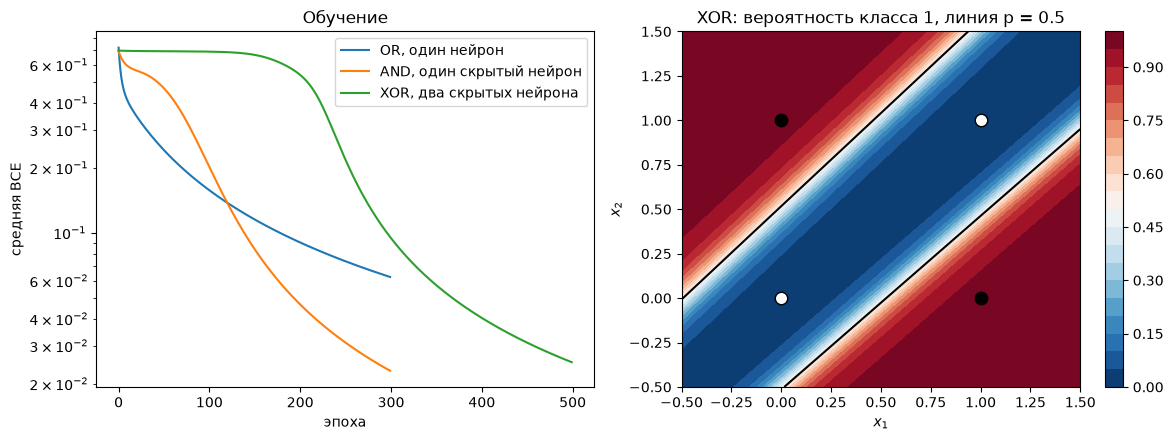

In [15]:
import matplotlib.pyplot as plt

for k in (1, 51, 101, 151, 201, 251, 301, 401, 500):
    print(f"XOR: эпоха {k}: loss = {xor_losses[k - 1]:.4f}")
print("XOR: первая эпоха с loss < 0.03:", next(i + 1 for i, l in enumerate(xor_losses) if l < 0.03))
print("XOR: веса:", [round(parameter.data, 3) for parameter in trained_xor.parameters()])
for features in XOR_INPUTS:
    hidden = [round(h.data, 3) for h in trained_xor.hidden_states(features)]
    print("XOR: скрытые состояния для", features, ":", hidden)

# сетка точек для карты вероятности
grid = [i / 20 for i in range(-10, 31)]
probability_map = [[trained_xor([x1, x2]).data for x1 in grid] for x2 in grid]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(or_losses, label="OR, один нейрон")
axes[0].plot(and_losses, label="AND, один скрытый нейрон")
axes[0].plot(xor_losses, label="XOR, два скрытых нейрона")
axes[0].set_yscale("log")
axes[0].set_xlabel("эпоха")
axes[0].set_ylabel("средняя BCE")
axes[0].set_title("Обучение")
axes[0].legend()

image = axes[1].contourf(grid, grid, probability_map, levels=20, cmap="RdBu_r")
axes[1].contour(grid, grid, probability_map, levels=[0.5], colors="black")
for features, target in zip(XOR_INPUTS, XOR_TARGETS):
    axes[1].scatter(*features, c="white" if target == 0 else "black", edgecolors="black", s=80)
axes[1].set_xlabel("$x_1$")
axes[1].set_ylabel("$x_2$")
axes[1].set_title("XOR: вероятность класса 1, линия p = 0.5")
fig.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

**Интерпретация обучения XOR.**

- BCE упала с $0.697490$ до $\approx 0.0251 < 0.03$, точность $1.0$. Вероятности: $p(0, 0) \approx 0.019$, $p(0, 1) \approx 0.968$, $p(1, 0) \approx 0.968$, $p(1, 1) \approx 0.016$.
- Кривая XOR сильно отличается от OR и AND: первые ~150 эпох loss почти стоит на месте (на 151-й эпохе ещё $\approx 0.666$), потом за 150 эпох падает до $\approx 0.094$ (301-я эпоха), а порог $0.03$ проходит только на 458-й эпохе из 500. Это то самое «плато» из-за маленьких начальных градиентов: скрытым нейронам сначала нужно разойтись по ролям.
- Итоговые веса: первый скрытый нейрон $u_1 \approx (1.347,\ 2.974,\ -2.838)$, второй $u_2 \approx (1.544,\ -3.173,\ 3.246)$, выход $v \approx (3.779,\ -4.346,\ -4.309)$. Первый нейрон отрицателен только в точке $(0, 1)$ ($h_1 \approx -0.903$, в остальных $\approx 0.87$–$1.0$), второй — только в точке $(1, 0)$ ($h_2 \approx -0.926$). То есть каждый нейрон выучил свою «половину» XOR: $x_2$ и не $x_1$, $x_1$ и не $x_2$.
- Выход $o = 3.779 - 4.346h_1 - 4.309h_2$ большой, только если один из $h$ отрицательный. Для $(0, 0)$: $o \approx 3.779 - 4.346 \cdot 0.873 - 4.309 \cdot 0.913 \approx -3.95$, $p \approx 0.019$; для $(0, 1)$: $o \approx 3.779 + 4.346 \cdot 0.903 - 4.309 \cdot 1.0 \approx 3.40$, $p \approx 0.968$.
- На карте видно, что линия $p = 0.5$ состоит из двух почти параллельных линий. Точки $(0, 0)$ и $(1, 1)$ (класс 0) лежат в синей полосе между ними, а $(0, 1)$ и $(1, 0)$ (класс 1) — по разные стороны снаружи полосы. Каждая линия проходит примерно там, где меняет знак один из скрытых нейронов: верхняя — $h_1$ ($x_2 \approx 1.05x_1 + 0.47$), нижняя — $h_2$ ($x_2 \approx 0.98x_1 - 0.48$). Одной прямой так сделать нельзя, это и есть выигрыш от двух скрытых нейронов.

## Диагностика

Все проверки прошли с первого запуска, поэтому ничего исправлять не пришлось. Итог трёх этапов:

| Этап | Модель | Начальная BCE | Финальная BCE | Порог | Accuracy |
|---|---|---|---|---|---|
| OR | один sigmoid-нейрон | 0.720020 | 0.0624 | 0.1 | 1.0 |
| AND | 1 скрытый tanh + sigmoid | 0.693386 | 0.0229 | 0.05 | 1.0 |
| XOR | 2 скрытых tanh + sigmoid | 0.697490 | 0.0251 | 0.03 | 1.0 |

Если бы что-то упало, по guide нужно проверять: порядок запуска ячеек, что весов на один больше, чем признаков (вес $w_0$ для постоянной единицы), что sigmoid только на выходе, а tanh только в скрытом слое, что `loss.backward()` идёт до обновления, знак шага $-\eta g$, порог $0.5$ и разные начальные веса скрытых нейронов XOR.

## Чек-лист перед сдачей

- [x] Все `assert` пройдены, ноутбук выполнен сверху вниз без ошибок.
- [x] Центральная разность совпала с autograd для OR (3 параметра), AND (5 параметров) и XOR (9 параметров) с допуском $10^{-5}$.
- [x] Объяснено, почему `features` не входят в `parameters()`: признаки — это данные объекта, а не то, что модель учит. В `affine` число-признак временно оборачивается в константный лист `Value`, он получает `grad`, но на следующем объекте и следующей эпохе создаётся заново и никуда не сохраняется. Обучаются только долгоживущие веса, на которые ссылается `parameters()`.
- [x] Показано, где один параметр используется всеми объектами выборки: в `mean_binary_cross_entropy` цикл вызывает `model(features)` для каждого из четырёх объектов, и каждый вызов `affine` берёт те же объекты `weights[0]`, `weights[1]`, `weights[2]`. Поэтому `backward()` складывает в `weights[0].grad` четыре вклада $(p_\mu - y_\mu)/4$; для OR это $-0.262458$.
- [x] Получены требуемые loss и accuracy: OR $0.0624 < 0.1$, AND $0.0229 < 0.05$, XOR $0.0251 < 0.03$, везде accuracy $1.0$.
- [x] Объяснено, почему одного скрытого нейрона недостаточно для XOR: после монотонных $\tanh$ и sigmoid с порогом $0.5$ решение задаётся одной прямой, а для XOR $f(0, 1) + f(1, 0) = f(0, 0) + f(1, 1)$ не даёт разделить классы (раздел «Зачем в маршруте нужен XOR»).

## Ответы на вопросы для самопроверки

**1. Какие скалярные вершины создаёт `affine` для двух признаков, включая путь $w_0 \cdot 1$?**
Сначала константный лист `Value(1.0)` и узел `*` для $w_0 \cdot 1$. Потом для каждого признака константный лист `Value(x_j)`, узел `*` для $w_j x_j$ и узел `+`, который прибавляет его к сумме. Итого три листа-константы, три умножения и два сложения: $((w_0 \cdot 1) + w_1 x_1) + w_2 x_2$. Сами веса $w_0, w_1, w_2$ — уже существующие листы.

**2. Почему одна ссылка на `weights[0]` даёт сумму градиентных вкладов от всех объектов датасета?**
Потому что для всех четырёх объектов в граф попадает один и тот же объект `weights[0]`, а не его копия. После сложения потерь он становится родителем четырёх разных узлов `*`, и при `backward()` каждый из них делает `+=` в одно поле `grad`. Получается $\sum_\mu (p_\mu - y_\mu)/n$ — ровно формула производной средней потери.

**3. Какой узел хранит вероятность класса 1: скрытый tanh-узел или выход sigmoid?**
Выход sigmoid: его значение лежит в $(0, 1)$ и именно оно идёт в BCE и в порог $0.5$. Скрытый $\tanh$ даёт число в $(-1, 1)$ — это промежуточный признак, вероятностью он не является.

**4. Почему binary cross-entropy совместно с sigmoid даёт для выходного logit градиент $p - y$?**
$\partial \ell / \partial p = -y/p + (1 - y)/(1 - p)$, а $\partial p / \partial o = p(1 - p)$. При умножении знаменатели сокращаются: $-y(1 - p) + (1 - y)p = p - y$. Поэтому градиент по логиту не затухает, даже если sigmoid сильно насыщен, и пропорционален тому, насколько ошибся прогноз.

**5. Что нарушится, если обновить `parameter.data` до `loss.backward()`?**
Замыкания `_backward` читают `data` в момент обратного прохода (например, `other.data` в умножении). Граф построен для старых весов, а производные посчитаются с новыми — получится смесь двух точек, и градиент будет неверный. Кроме того, до `backward()` в `grad` лежит градиент прошлой эпохи, то есть шаг сделали бы по устаревшему направлению.

**6. Почему два одинаково инициализированных скрытых нейрона не приобретают разные роли?**
Если веса нейронов и их выходные веса совпадают, то для каждого объекта у них одинаковые $h$ и одинаковые градиенты $g_{r_{ih}} = g_{o_i} v_h (1 - h_{ih}^2)$. После шага они снова одинаковые, и так на каждой эпохе. Фактически получается один нейрон, повторённый дважды, а одним нейроном XOR не решить. Поэтому в `train_xor` начальные веса разные: $(0.1,\ 0.4,\ -0.3)$ и $(-0.1,\ -0.2,\ 0.5)$.

**7. Почему XOR в этой лабораторной является тестом выразительности, а не прикладной целевой задачей?**
Сам XOR из четырёх точек никому не нужно классифицировать. Это самый маленький датасет, который нельзя разделить одной прямой, поэтому на нём сразу видно, может архитектура построить нелинейную границу или нет. Один нейрон (и один скрытый нейрон) не может, два скрытых нейрона — могут. В реальной MLP тот же принцип работает с большим числом признаков и нейронов.